# Dockstring BO Plots

Edit `DOCKSTRING_SOURCES` to choose which baselines to compare and where their saved results live.
This notebook expects the same artifact format as `scripts/evaluate_bo.py`: `metadata.json` plus `regret.npy` / `normalized_regret.npy`.


In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

%load_ext autoreload
%autoreload 2


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists() or (candidate / ".git").exists():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd().resolve())
SRC_ROOT = REPO_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from polar.utils.plotting import PAPER_COLORS, apply_style  # noqa: E402

apply_style(use_tex=True, base_font_size=20)


In [2]:
METHOD_COLORS = {
    "POLAR": PAPER_COLORS[1],
    "TabICL": PAPER_COLORS[5],
    "GP (Tanimoto)": PAPER_COLORS[0],
    "Random": PAPER_COLORS[6],
}
METHOD_MARKERS = {
    "POLAR": "*",
    "TabICL": "X",
    "GP (Tanimoto)": "o",
    "Random": "^",
}


def load_bo_method_artifact(path: Path | str, metric: str = "regret") -> dict:
    method_dir = Path(path).expanduser().resolve()
    metadata_path = method_dir / "metadata.json"
    if not metadata_path.exists():
        raise FileNotFoundError(f"Missing metadata.json under {method_dir}")

    metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    artifact_files = metadata.get("artifact_files", {})
    metric_file = artifact_files.get(metric, f"{metric}.npy")
    metric_path = method_dir / metric_file if not Path(metric_file).is_absolute() else Path(metric_file)
    if not metric_path.exists():
        raise FileNotFoundError(f"Missing {metric}.npy under {method_dir}")

    curves = np.load(metric_path)
    return {
        "method_dir": method_dir,
        "metadata": metadata,
        "metric": metric,
        "curves": curves,
        "rounds": np.asarray(metadata["rounds"], dtype=np.int64),
    }


def _trim_loaded_artifacts_to_common_rounds(loaded: list[dict]) -> tuple[list[dict], np.ndarray]:
    common_len = min(len(artifact["rounds"]) for artifact in loaded)
    rounds = np.asarray(loaded[0]["rounds"][:common_len], dtype=np.int64)
    trimmed = []
    for artifact in loaded:
        trimmed_artifact = artifact.copy()
        trimmed_artifact["rounds"] = np.asarray(artifact["rounds"][:common_len], dtype=np.int64)
        trimmed_artifact["curves"] = artifact["curves"][..., :common_len]
        trimmed.append(trimmed_artifact)
    return trimmed, rounds


def _mean_stderr_from_stack(stacked: np.ndarray) -> dict[str, np.ndarray]:
    counts = np.sum(~np.isnan(stacked), axis=0)
    means = np.nanmean(stacked, axis=0)
    stds = np.nanstd(stacked, axis=0)
    stderrs = np.divide(
        stds,
        np.sqrt(np.maximum(counts, 1)),
        out=np.zeros_like(stds),
        where=counts > 0,
    )
    return {
        "mean": means,
        "stderr": stderrs,
        "counts": counts,
    }


def aggregate_bo_curves(curves: np.ndarray) -> dict[str, np.ndarray]:
    if curves.ndim != 3:
        raise ValueError(f"Expected curves with shape [n_datasets, n_seeds, n_rounds], got {curves.shape}")
    flat = curves.reshape(-1, curves.shape[-1])
    return _mean_stderr_from_stack(flat)


def _compute_log_floor(loaded: list[dict]) -> float:
    positive_values = []
    for artifact in loaded:
        positive_values.extend(artifact["aggregate"]["mean"][artifact["aggregate"]["mean"] > 0.0].tolist())
        positive_values.extend(artifact["aggregate"]["stderr"][artifact["aggregate"]["stderr"] > 0.0].tolist())
    return max(min(positive_values) * 0.1, 1e-12) if positive_values else 1e-12


def plot_dockstring_curve_block(
    sources: dict[str, Path | str | None],
    *,
    metric: str = "regret",
    title: str = "DOCKSTRING",
    marker_every: int = 5,
    show_legend: bool = True,
    log_scale: bool = False,
    y_margin_ratio: float = 0.08,
    save_path: Path | str | None = None,
):
    loaded = []
    for label, source in sources.items():
        if source is None:
            continue
        method_dir = Path(source).expanduser().resolve()
        if not method_dir.exists():
            print(f"Skipping {label}: {method_dir} not found")
            continue
        artifact = load_bo_method_artifact(method_dir, metric=metric)
        artifact["label"] = label
        loaded.append(artifact)

    if not loaded:
        raise ValueError("No Dockstring artifacts were loaded.")

    loaded, rounds = _trim_loaded_artifacts_to_common_rounds(loaded)
    for artifact in loaded:
        artifact["aggregate"] = aggregate_bo_curves(artifact["curves"])

    use_log_scale = bool(log_scale)
    log_floor = _compute_log_floor(loaded) if use_log_scale else None
    all_lowers = []
    all_uppers = []

    fig, ax = plt.subplots(figsize=(6, 5))
    for method_idx, artifact in enumerate(loaded):
        label = artifact["label"]
        means = artifact["aggregate"]["mean"]
        stderrs = artifact["aggregate"]["stderr"]

        if use_log_scale:
            means_to_plot = np.maximum(means, log_floor)
            lower = np.maximum(means - stderrs, log_floor)
            upper = np.maximum(means + stderrs, log_floor)
        else:
            means_to_plot = means
            lower = np.maximum(means - stderrs, 0.0)
            upper = means + stderrs

        all_lowers.append(lower)
        all_uppers.append(upper)

        color = METHOD_COLORS.get(label, PAPER_COLORS[method_idx % len(PAPER_COLORS)])
        marker = METHOD_MARKERS.get(label, "o")
        markersize = 15 if marker == "*" else 9
        markevery = list(range(0, len(rounds), marker_every)) if marker_every > 0 else None

        ax.plot(
            rounds,
            means_to_plot,
            color=color,
            linewidth=2.5,
            # drawstyle="steps-post",
            marker=marker,
            markersize=markersize,
            markeredgewidth=1.2 if marker == "*" else 1.0,
            markevery=markevery,
            label=label,
        )
        ax.fill_between(rounds, lower, upper, color=color, alpha=0.14)

    y_label = "Average Regret" if metric == "regret" else "Normalized Regret"
    ax.set_title(title)
    ax.set_xlabel("Acquisition step", fontsize=27)
    ax.set_ylabel(y_label, fontsize=27)
    if use_log_scale:
        ax.set_yscale("log")
        ax.set_ylim(bottom=log_floor)
    else:
        y_min = float(np.nanmin(np.concatenate(all_lowers)))
        y_max = float(np.nanmax(np.concatenate(all_uppers)))
        y_span = max(y_max - y_min, 1e-6)
        y_margin = float(y_margin_ratio) * y_span
        ax.set_ylim(max(0.0, y_min - y_margin), y_max + y_margin+0.3)
        # ax.set_ylim(0, 0.45)
    ax.grid(alpha=0.25)

    if show_legend:
        ax.legend(
            loc="upper right",
            fontsize=19,
            frameon=True,
            handlelength=1.2,
            handletextpad=0.45,
            labelspacing=0.35,
            borderpad=0.35,
        )

    if save_path is not None:
        save_path = Path(save_path).expanduser().resolve()
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    return fig, ax, loaded


In [ ]:
RESULTS_ROOT = REPO_ROOT / "notebooks/final_results/dockstring"
DOCKSTRING_PDF = REPO_ROOT / "figures" / "dockstring_regret.pdf"

# Edit labels or paths here.
DOCKSTRING_SOURCES = {
    "Random": RESULTS_ROOT / "random",
    "GP (Tanimoto)": RESULTS_ROOT / "gp_tanimoto_ei",
    # "GP (RBF)": RESULTS_ROOT / "gp_rbf_ei",
    "Random Forest": RESULTS_ROOT / "rf_ei",
    "TabICL": RESULTS_ROOT / "tabicl_ei_mc",
    "POLAR": RESULTS_ROOT / "polar",
}

sorted(p.name for p in RESULTS_ROOT.iterdir() if p.is_dir())


['gp_rbf_ei', 'gp_tanimoto_ei', 'polar', 'random', 'rf_ei', 'tabicl_ei_mc']

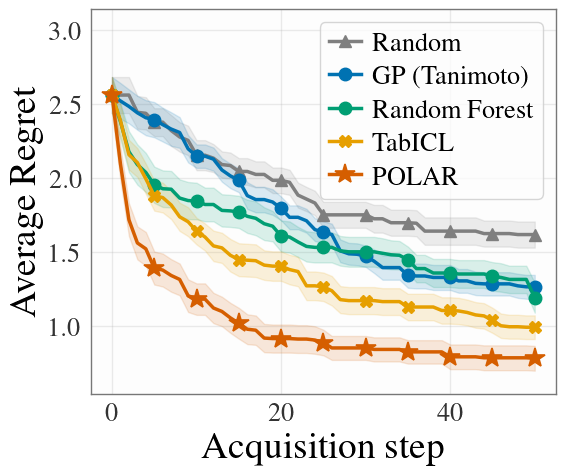

[('Random', 'random'),
 ('GP (Tanimoto)', 'gp_ei'),
 ('Random Forest', 'rf_ei'),
 ('TabICL', 'tabicl_ei_mc'),
 ('POLAR', 'polar')]

In [4]:
fig, ax, loaded = plot_dockstring_curve_block(
    DOCKSTRING_SOURCES,
    metric="regret",
    title="",
    marker_every=5,
    save_path=DOCKSTRING_PDF,
)
display(fig)
plt.close(fig)

[(artifact["label"], artifact["metadata"].get("method")) for artifact in loaded]
